In [16]:
import pandas as pd
import json
import matplotlib.pyplot as plt

In [17]:
MODELS = [
    "llama-70b",
    "qwen-32b",
    "qwen-14b",
]

In [58]:
df = pd.read_csv("../../datasets/data/eval_datasets/eval_dataset-llama70b.csv")
results = json.load(open("../../datasets/data/eval_results/results.comparison.json"))
df = df.rename(columns={"generation": "generation_llama-70b"})
if "qwen-14b" in MODELS:
    df_qwen14b = pd.read_csv("../../datasets/data/eval_datasets/eval_dataset-qwen14b.csv")
    df["generation_qwen-14b"] = df_qwen14b["generation"]
    del df_qwen14b
if "qwen-32b" in MODELS:
    df_qwen32b = pd.read_csv("../../datasets/data/eval_datasets/eval_dataset-qwen32b.csv")
    df["generation_qwen-32b"] = df_qwen32b["generation"]
    del df_qwen32b

In [59]:
for model in MODELS:
    scores = results["models"][model]["semantic_similarity"]["individual_scores"]
    df["score_" + model] = scores

## Evaluation Dataset Overview

In [20]:
print(df.keys())

Index(['instruction', 'groundtruth', 'subject', 'exercise_type', 'grade_level',
       'modifier', 'generation_llama-70b', 'generation_qwen-14b',
       'generation_qwen-32b', 'score_llama-70b', 'score_qwen-32b',
       'score_qwen-14b'],
      dtype='object')


In [21]:
print(df.groupby("subject").size().sort_values(ascending=False), "\n")
print(df.groupby("exercise_type").size().sort_values(ascending=False).head(10), "\n")
print(df[df["subject"] != "Mathematics"].groupby("exercise_type").size().sort_values(ascending=False).head(10))


subject
Mathematics         515
Science              91
Geography            45
English              44
French               38
Computer Science     35
Social Studies       25
Dutch                23
Spanish              20
History              19
German                5
dtype: int64 

exercise_type
Arithmetic Exercise                                144
Word Problem, Arithmetic Exercise                   74
Short Answer Exercise                               43
Arithmetic Exercise, Word Problem                   33
Question Exercise                                   32
Grammar Exercise                                    30
Arithmetic Exercise, Fill in the Blank Exercise     24
Writing Exercise                                    22
Multiple Choice Exercise                            21
Fill in the Blank Exercise                          19
dtype: int64 

exercise_type
Short Answer Exercise             42
Question Exercise                 32
Grammar Exercise                  30
Multiple 

## Semantic Similarity Scores

In [22]:
MODELS = [
    "llama-70b",
    # "qwen-32b",
    # "qwen-14b",
]

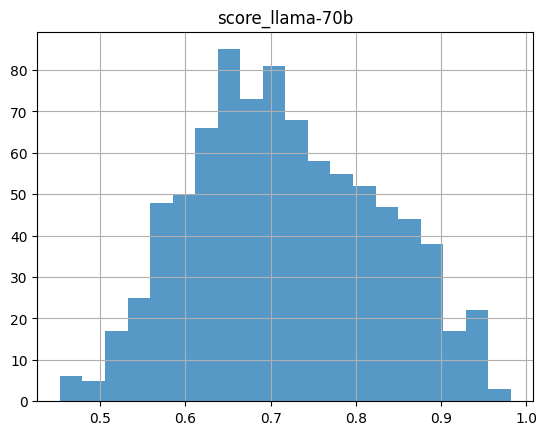

In [23]:
for m in MODELS:
    df.hist(column="score_"+m, bins=20, alpha=0.75, label=m)

### By Subject

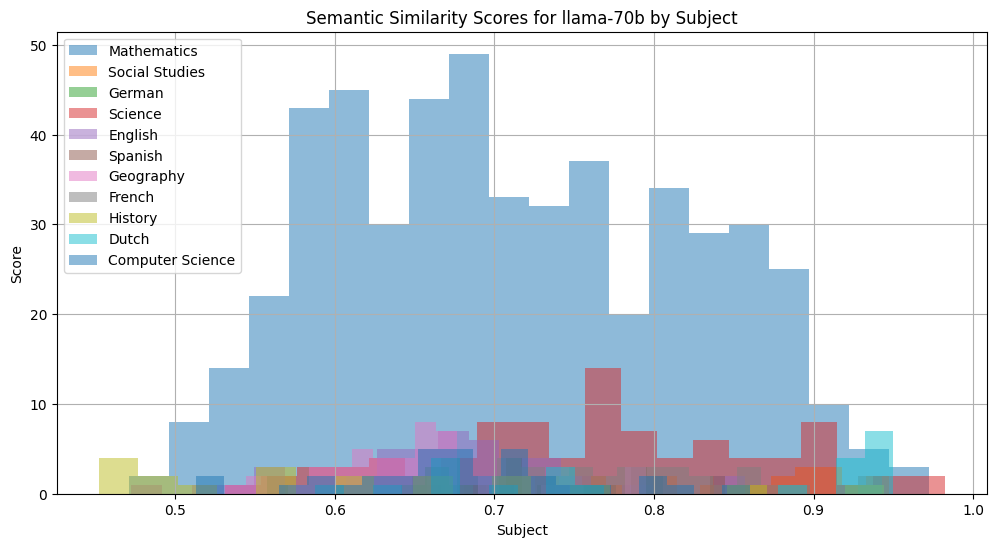

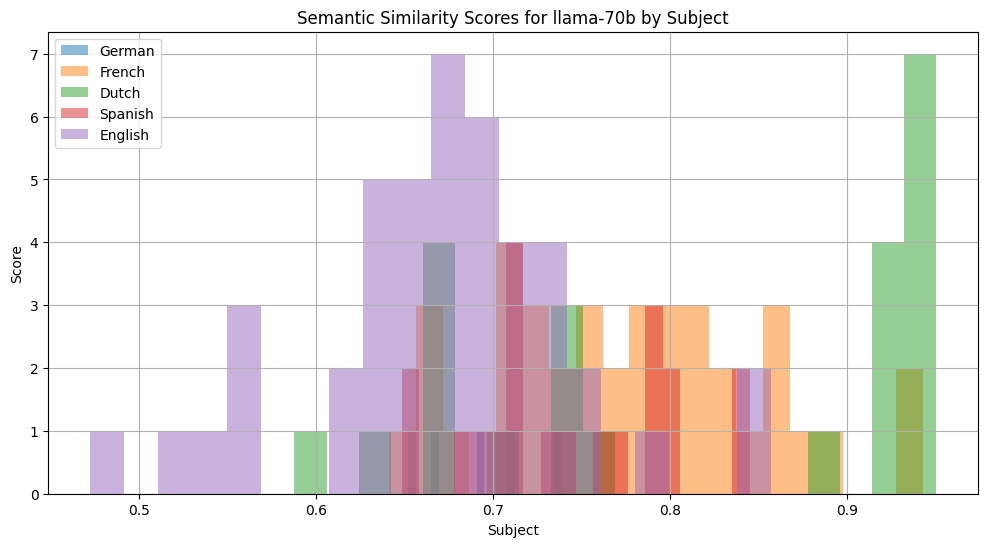

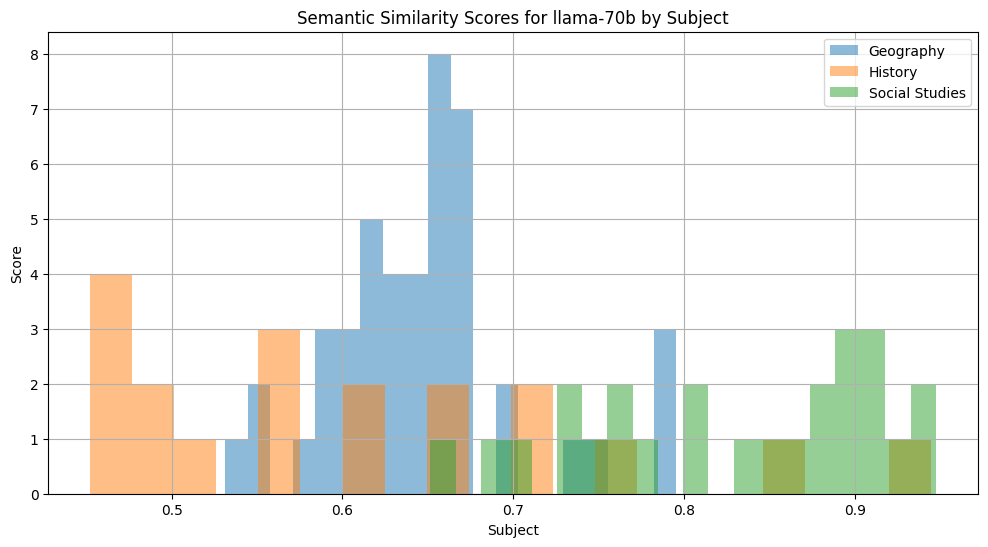

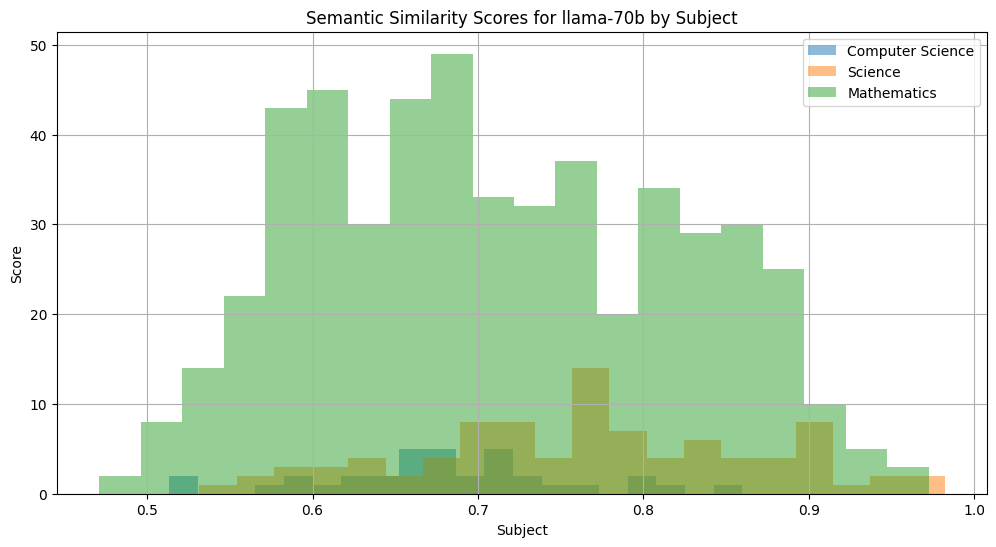

In [24]:
subject_groups = {"all": df.subject.unique(),
                  "languages": ['German', 'French', 'Dutch', 'Spanish', 'English'],
                  "social_sciences": ['Geography', 'History', 'Social Studies'],
                  "science": ['Computer Science', 'Science', 'Mathematics']}
for subjects_oi in subject_groups.values():
    for m in MODELS:
        fig, ax = plt.subplots(1,1,figsize=(12, 6))
        for subj in subjects_oi:
            sub_df = df[df["subject"] == subj]
            sub_df.hist(column="score_"+m, bins=20, alpha=0.5, ax=ax)
        ax.set_xlabel("Subject")
        ax.set_ylabel("Score")
        ax.set_title(f"Semantic Similarity Scores for {m} by Subject")
        ax.legend(subjects_oi)
        plt.show()

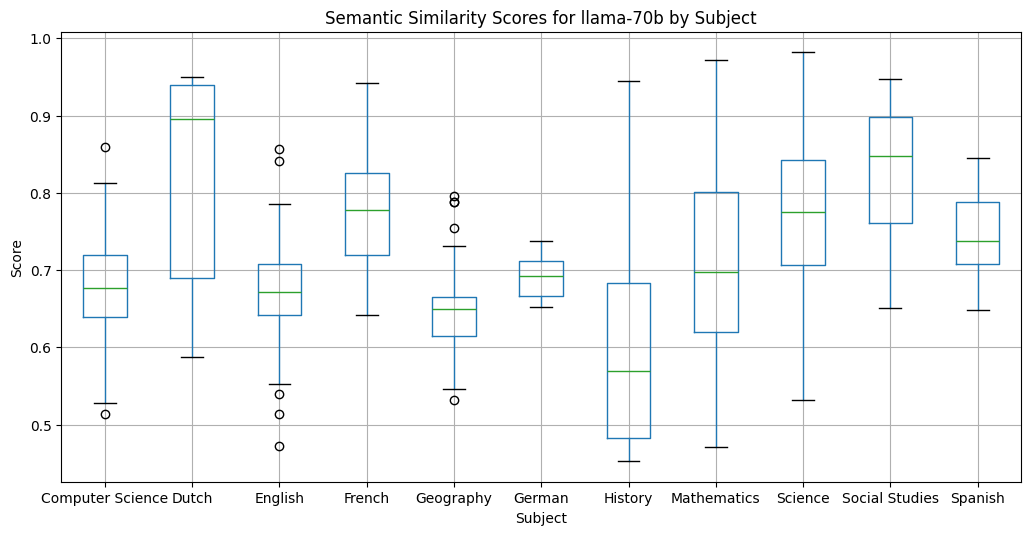

In [25]:
for m in MODELS:
    fig, ax = plt.subplots(1,1,figsize=(12, 6))
    df.boxplot(column="score_"+m, by="subject", ax=ax)
    ax.set_xlabel("Subject")
    ax.set_ylabel("Score")
    ax.set_title(f"Semantic Similarity Scores for {m} by Subject")
    plt.suptitle("")
    plt.show()

### By Exercise Type

exercise_type
Arithmetic Exercise           305
Word Problem                  148
Fill in the Blank Exercise     84
Short Answer Exercise          77
Question Exercise              36
Grammar Exercise               35
Drawing Exercise               34
Writing Exercise               33
Geometry Exercise              23
Multiple Choice Exercise       22
Name: count, dtype: int64
exercise_type
Short Answer Exercise         67
Question Exercise             36
Grammar Exercise              35
Writing Exercise              29
Multiple Choice Exercise      22
Question                      21
Activity                      20
Translation Exercise          15
Research Exercise             14
Fill in the Blank Exercise    11
Name: count, dtype: int64


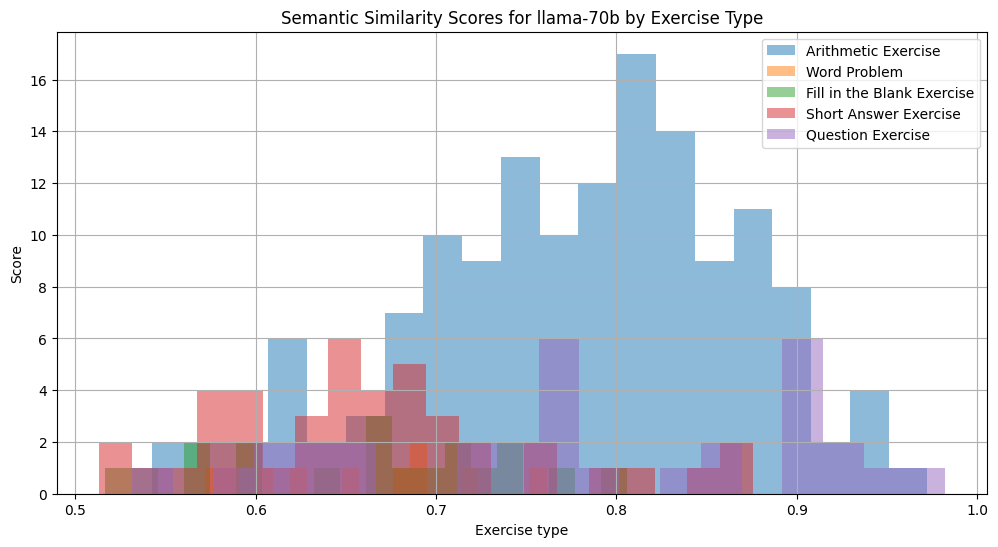

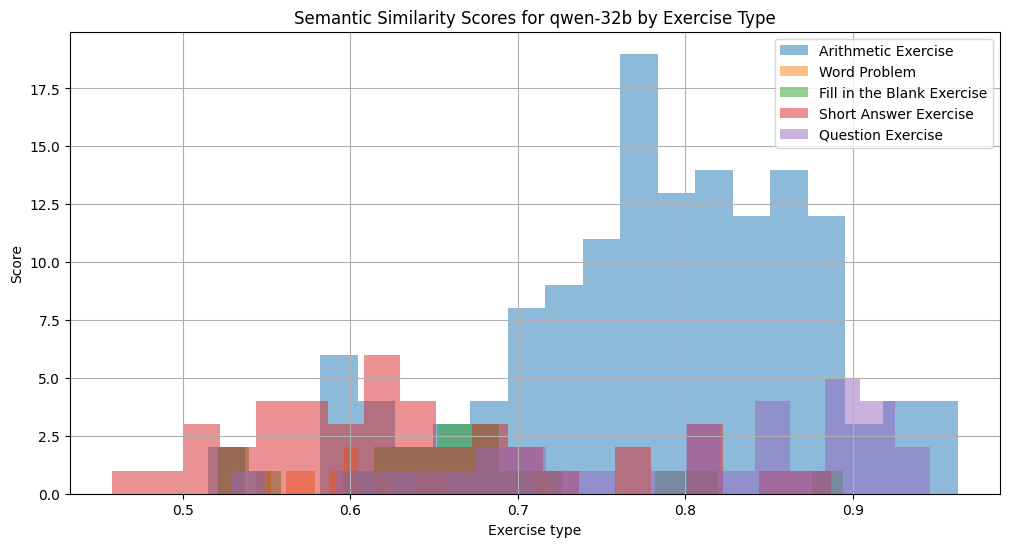

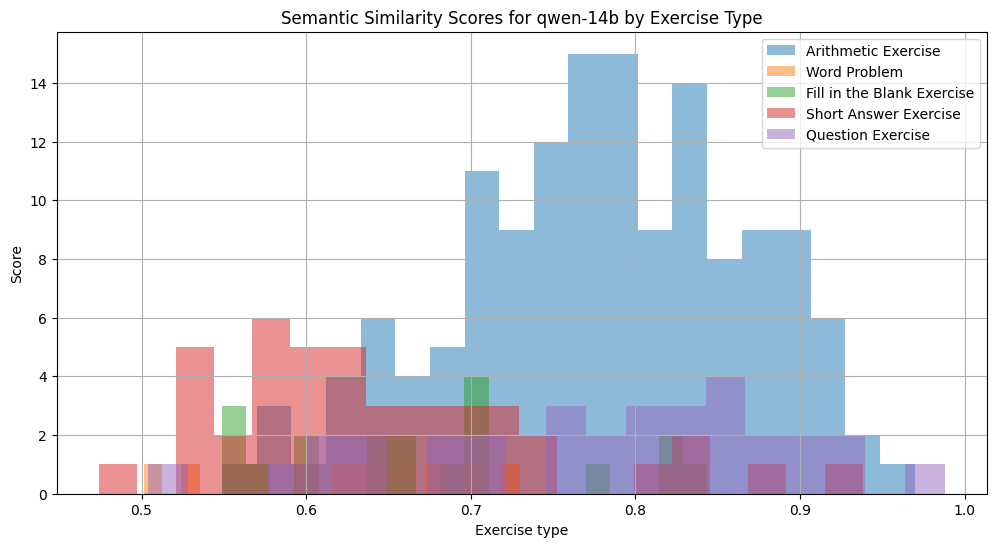

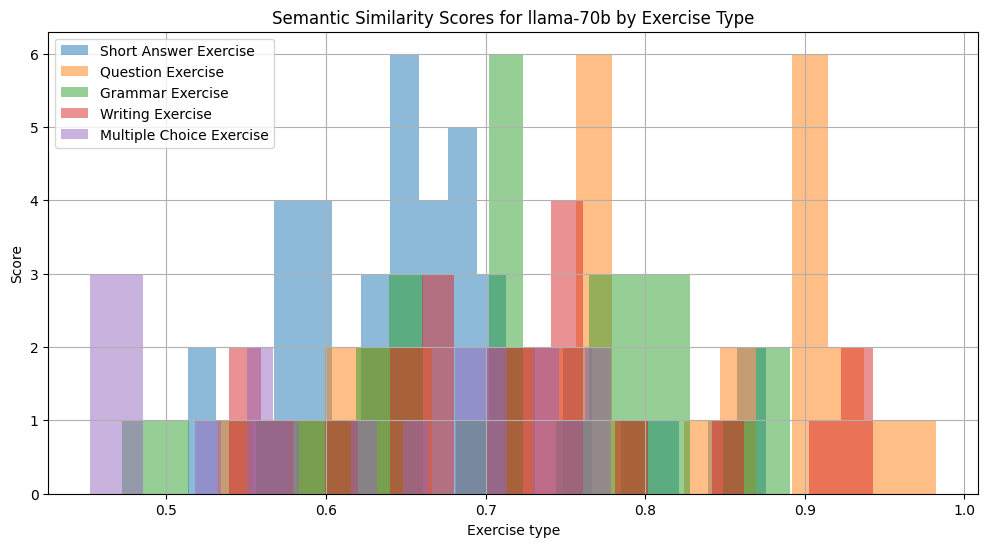

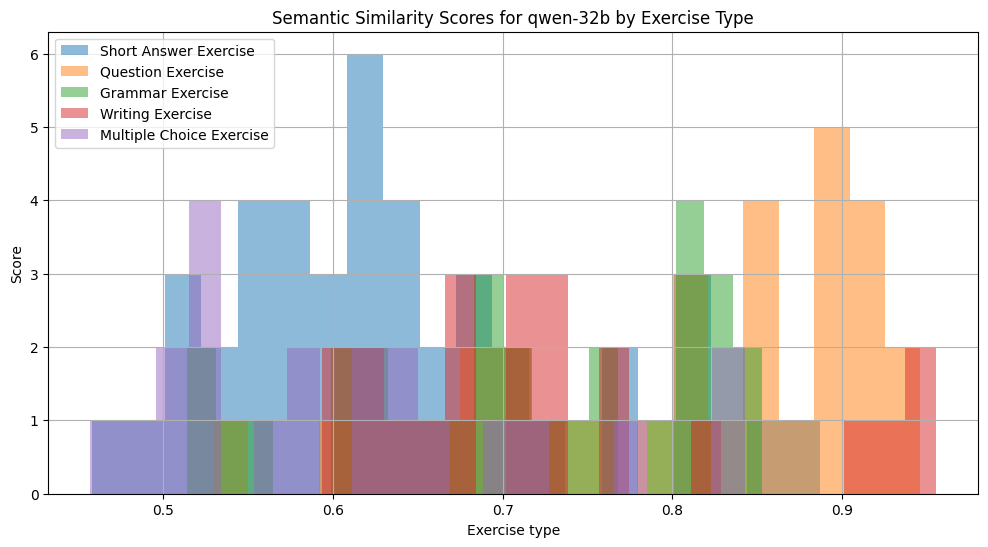

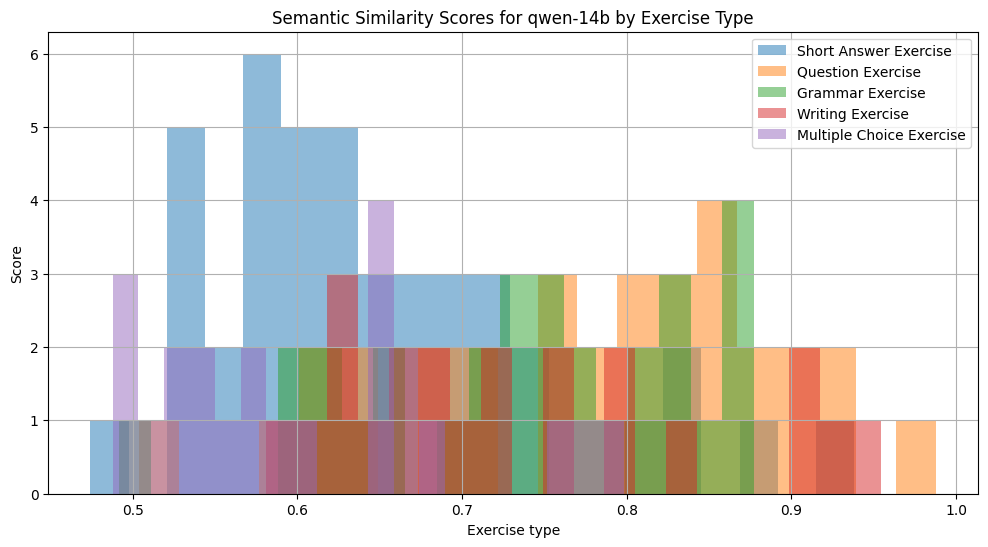

In [63]:
df_exploded = df.copy()
df_exploded["exercise_type"] = df_exploded["exercise_type"].str.split(", ")
df_exploded = df_exploded.explode("exercise_type")

types_sorted = df_exploded["exercise_type"].value_counts()
print(types_sorted[:10])
types_sorted_nm = df_exploded[df_exploded["subject"] != "Mathematics"]["exercise_type"].value_counts()
print(types_sorted_nm[:10])

exercise_types = {"top5": types_sorted.index.tolist()[:5],
                  "top5_no_math": types_sorted_nm.index.tolist()[:5],
                  }

for types_oi in exercise_types.values():
    for m in MODELS:
        fig, ax = plt.subplots(1,1,figsize=(12, 6))
        for type in types_oi:
            sub_df = df[df["exercise_type"] == type]
            sub_df.hist(column="score_"+m, bins=20, alpha=0.5, ax=ax)
        ax.set_xlabel("Exercise type")
        ax.set_ylabel("Score")
        ax.set_title(f"Semantic Similarity Scores for {m} by Exercise Type")
        ax.legend(types_oi)
        plt.show()

Full exercise types, multiple types are left together

In [64]:
scores_by_type = df.groupby("exercise_type")["score_llama-70b"].mean().sort_values(ascending=False)
print(scores_by_type.head(10))
print(scores_by_type.tail(10))

exercise_type
Group Activity, Campaign Exercise                                                                                0.945171
Word Completion Exercise                                                                                         0.942264
Word Scramble Exercise                                                                                           0.929169
Sequence Exercise, Arithmetic Exercise                                                                           0.900950
Investigation, Partner Activity                                                                                  0.898923
Investigation Exercise, Discussion Exercise, Drawing Exercise, Data Collection Exercise, Photography Exercise    0.897387
Group Activity, Investigation, Discussion Exercise                                                               0.893145
Group Activity, Writing Exercise                                                                                 0.888273
Long Answe

Split exercise types, multiple types are split

In [67]:
df_min_5 = df_exploded.groupby("exercise_type").filter(lambda x: len(x) >= 5)

scores_by_type = df_min_5.groupby("exercise_type")["score_llama-70b"].mean().sort_values(ascending=False)
print(scores_by_type)

exercise_type
Word Completion Exercise          0.942264
Word Scramble Exercise            0.929169
Long Answer Exercise              0.842326
True-False Exercise               0.839028
Diagram Exercise                  0.838120
Partner Activity                  0.811203
Investigation Exercise            0.801286
Geometry Exercise                 0.791386
Group Activity                    0.784789
Question Exercise                 0.777154
Creative Exercise                 0.771162
Ordering Exercise                 0.755793
Fill-in-the-Blanks Exercise       0.752497
Reading Comprehension Exercise    0.744395
Question                          0.732427
Translation Exercise              0.725588
Writing Exercise                  0.725310
Arithmetic Exercise               0.724431
Coloring Exercise                 0.719216
Comparison Exercise               0.718425
Grammar Exercise                  0.718340
Discussion Exercise               0.714952
Measurement Exercise              0.7130

Split exercise types without Mathematics, multiple types are split

In [99]:
df_min_5_nm = df_min_5[df_min_5["subject"] != "Mathematics"]
scores_by_type_nm = df_min_5_nm.groupby("exercise_type")["score_llama-70b"].mean().sort_values(ascending=False)
print(scores_by_type_nm)

exercise_type
Comparison Exercise               0.944419
Word Completion Exercise          0.942264
Word Scramble Exercise            0.929169
Diagram Exercise                  0.847454
Long Answer Exercise              0.842326
True-False Exercise               0.839028
Partner Activity                  0.811203
Investigation Exercise            0.801286
Creative Exercise                 0.795012
Group Activity                    0.782671
Question Exercise                 0.777154
Drawing Exercise                  0.767129
Matching Exercise                 0.759640
Fill-in-the-Blanks Exercise       0.752497
Reading Comprehension Exercise    0.744395
Discussion Exercise               0.736490
Question                          0.732427
Translation Exercise              0.725588
Writing Exercise                  0.718740
Grammar Exercise                  0.718340
Activity                          0.711028
Fill in the Blank Exercise        0.704393
Vocabulary Exercise               0.6865

### Boxplots by Exercise Type for (better?) comparison

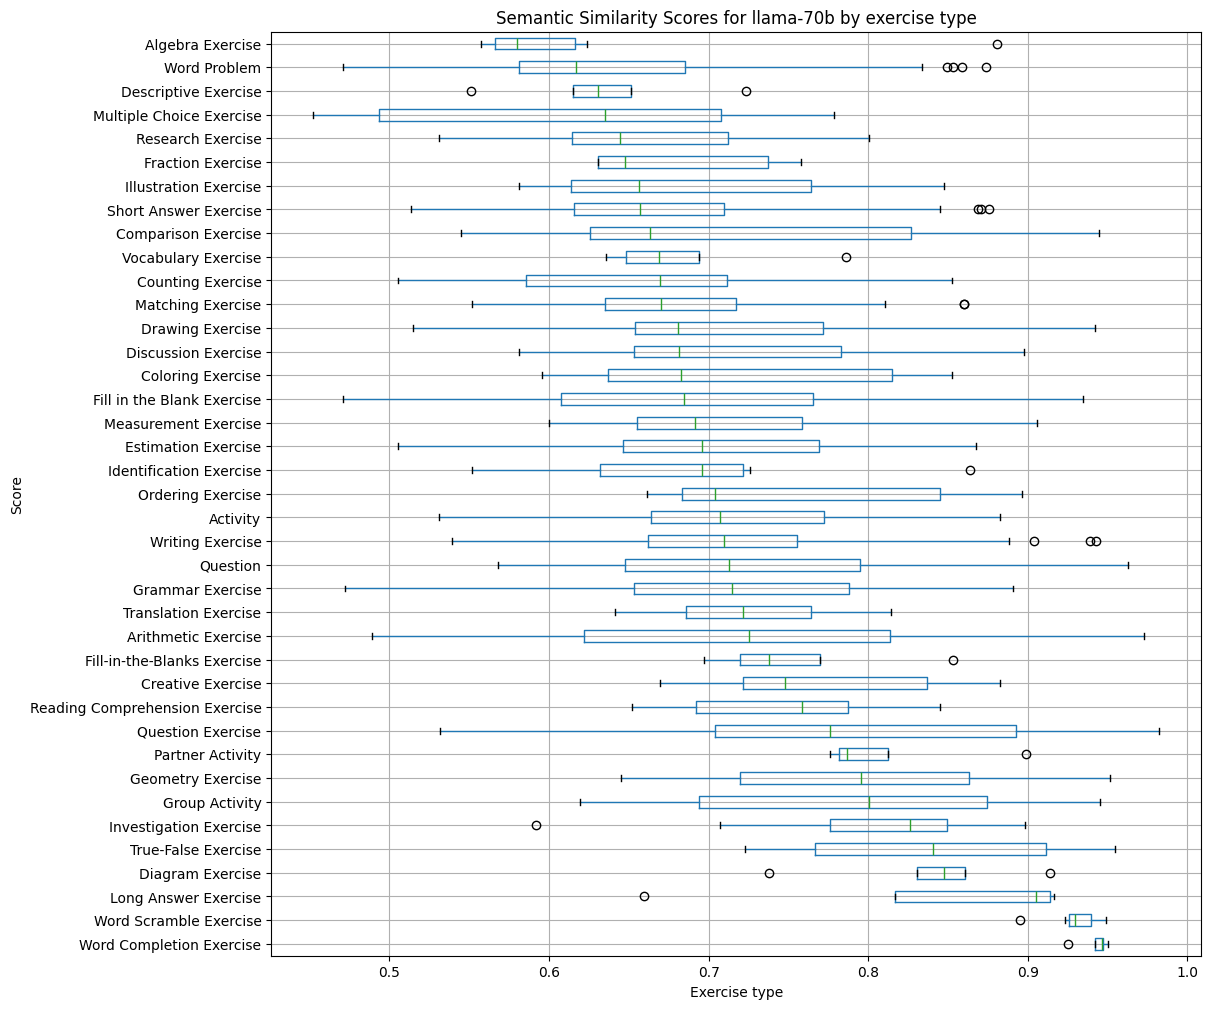

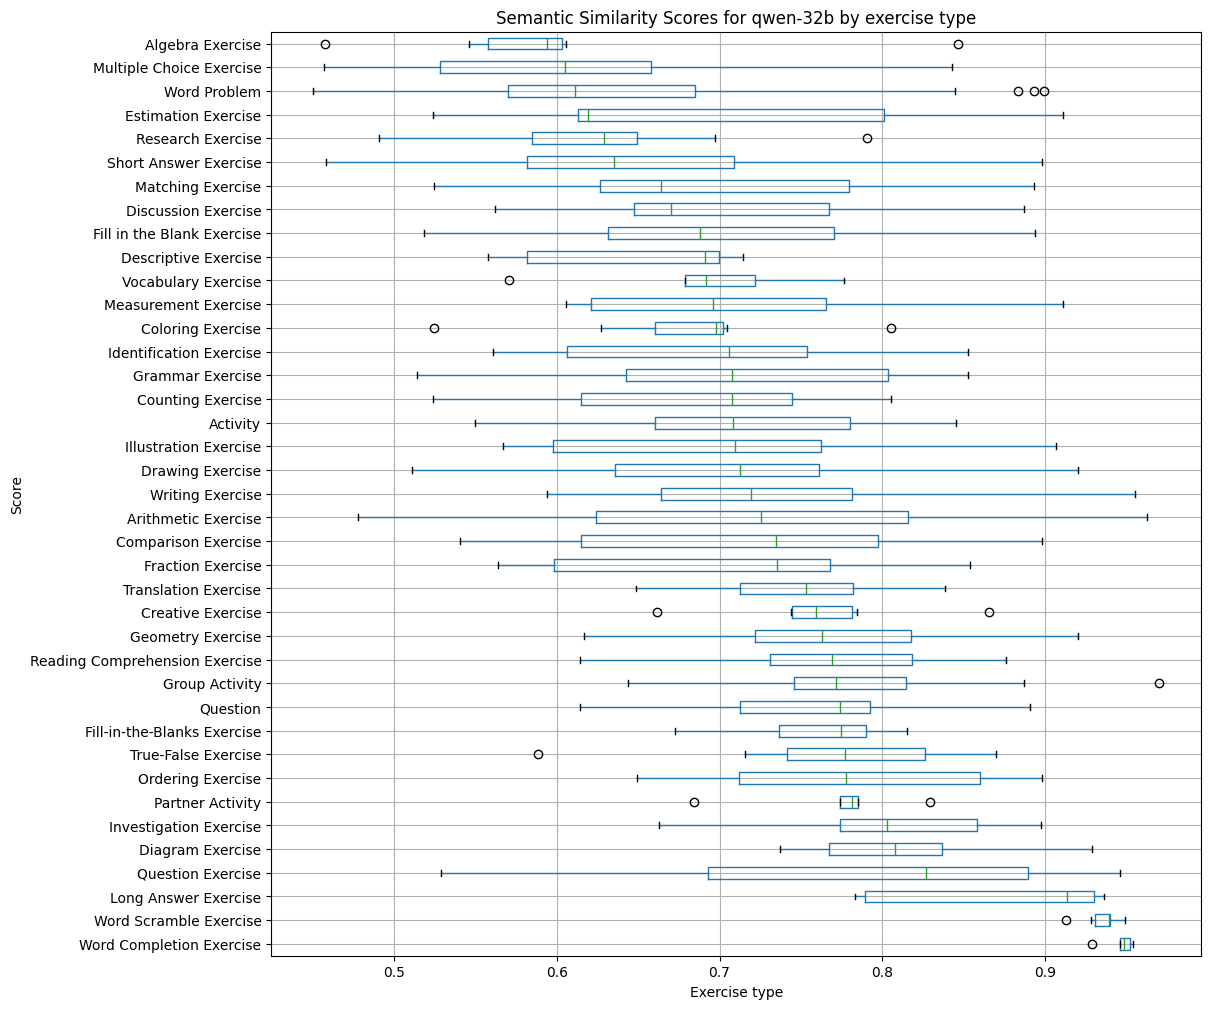

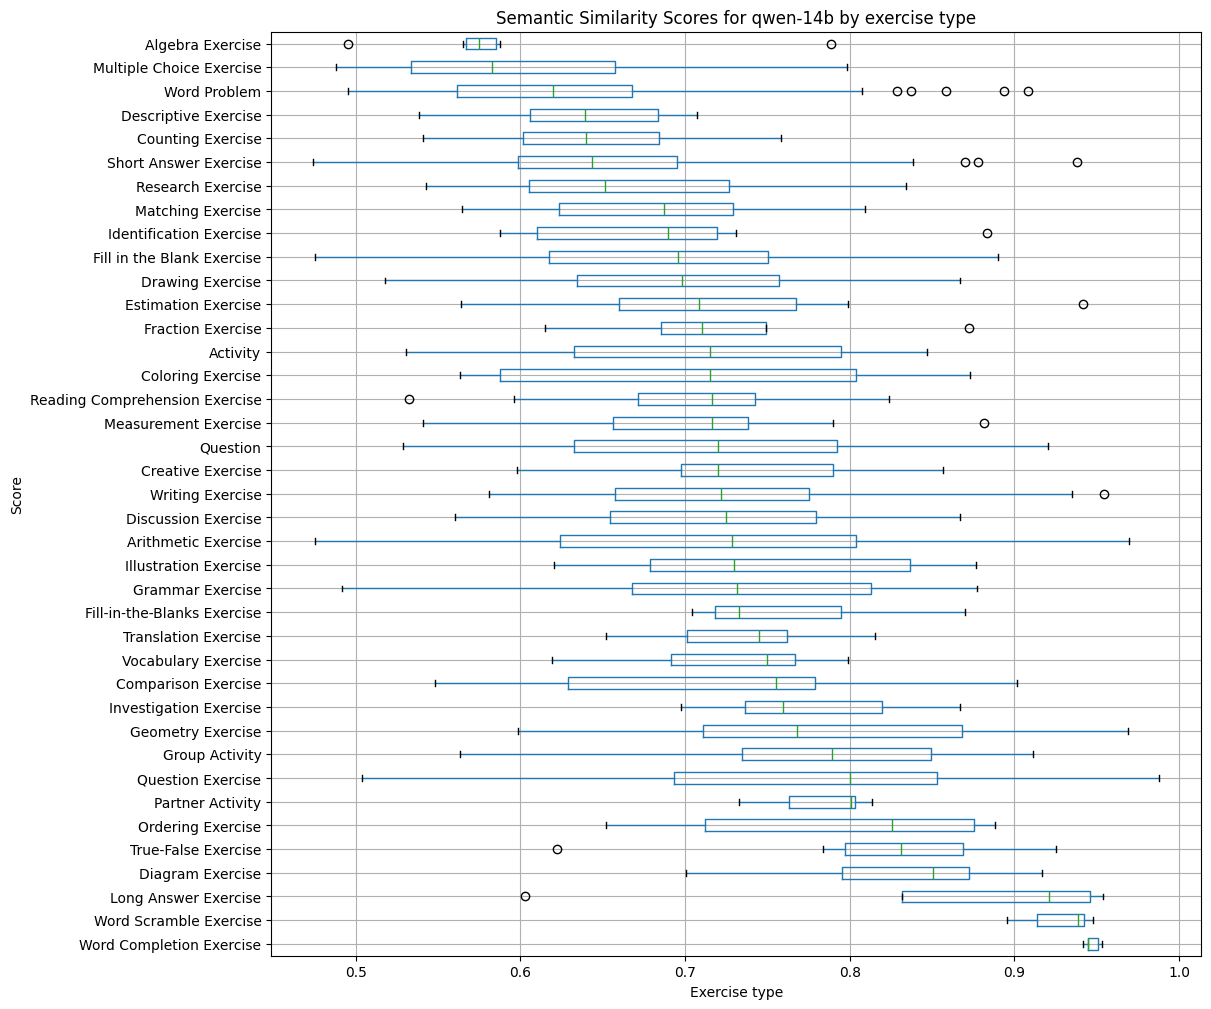

In [74]:
for m in MODELS:
    fig, ax = plt.subplots(1,1,figsize=(12, 12))
    # df_min_5.boxplot(column="score_"+m, by="exercise_type", ax=ax)

    grouped = df_min_5.groupby("exercise_type")
    df2 = pd.DataFrame({col:vals["score_"+m] for col,vals in grouped})

    meds = df2.median()
    meds.sort_values(ascending=False, inplace=True)
    df2 = df2[meds.index]
    df2.boxplot(ax=ax, fontsize=10, vert=False)

    ax.set_xlabel("Exercise type")
    ax.set_ylabel("Score")
    ax.set_title(f"Semantic Similarity Scores for {m} by exercise type")
    plt.suptitle("")
    plt.show()

## Manual Evaluation

Best and worst examples for each model by subject.

In [26]:
K = 5
for sub in subject_groups["all"]:
    print(f"#Subject: {sub}\n")
    sub_df = df[df["subject"] == sub]
    for m in MODELS:
        topk = sub_df.nlargest(n=K, columns=["score_"+m])
        for i in range(K):
            print(f"##Top {i+1} for {m} ({topk.iloc[i]['score_'+m]}):")
            print("[",
                  " | ".join(topk.iloc[i][['subject', 'exercise_type','grade_level', 'modifier']]),
                  "]\n")
            print("###Target:\n" + topk.iloc[i]["groundtruth"], "\n")
            print("###Generation:\n" + topk.iloc[i]["generation_"+m], "\n\n")


#Subject: Mathematics

##Top 1 for llama-70b (0.9725233912467957):
[ Mathematics | Arithmetic Exercise | 3 | Exercise with fraction addition ]

###Target:
\[
\frac{1}{6} + \frac{1}{6} + \frac{1}{6} + \frac{1}{6} =
\] 

###Generation:
\begin{enumerate}[label=\alph*.]
\item \( \frac{1}{4} + \frac{1}{4} = \)
\item \( \frac{1}{4} + \frac{1}{4} + \frac{1}{4} = \)
\end{enumerate} 


##Top 2 for llama-70b (0.9515435099601746):
[ Mathematics | Geometry Exercise | 3 | Exercise on identifying symmetry, With Illustration ]

###Target:
Draw the vertical and horizontal lines of symmetry on the following shapes: a square, a rectangle, and a circle.

[STRDGM] A square, a rectangle, a circle. [STPDGM] 

###Generation:
Draw the line of symmetry on each of these shapes.

[STRDGM] A square, a triangle, and a circle. [STPDGM] 


##Top 3 for llama-70b (0.9485356211662292):
[ Mathematics | Arithmetic Exercise | 1 | Exercise with addition, Multi-part ]

###Target:
Calculate the following addition problems:



In [27]:
for sub in subject_groups["all"]:
    print(f"#Subject: {sub}\n")
    sub_df = df[df["subject"] == sub]
    for m in MODELS:
        topk = sub_df.nsmallest(n=K, columns=["score_"+m])
        for i in range(K):
            print(f"##Lowest {i+1} for {m} ({topk.iloc[i]['score_'+m]}):")
            print("[",
                  " | ".join(topk.iloc[i][['subject', 'exercise_type','grade_level', 'modifier']]),
                  "]\n")
            print("###Target:\n" + topk.iloc[i]["groundtruth"], "\n")
            print("###Generation:\n" + topk.iloc[i]["generation_"+m], "\n\n")


#Subject: Mathematics

##Lowest 1 for llama-70b (0.47096946835517883):
[ Mathematics | Word Problem, Fill in the Blank Exercise | 3 | Multi-part ]

###Target:
Mingfa bought 420 red apples and 180 green apples altogether.

He sold a half of his apples.

There were \_\_\_\_ apples left. 

###Generation:
A florist has 18 bunches of flowers. Each bunch contains 5 flowers. How many flowers does the florist have in total?

The florist has \_\_\_\_\_\_ flowers. 


##Lowest 2 for llama-70b (0.4892321527004242):
[ Mathematics | Word Problem, Arithmetic Exercise | 3 | M ]

###Target:
A basket of rambutans weighs 150 kg. It is 112 kg lighter than a basket of durians. Find the weight of the basket of durians. 

###Generation:
Mr. Wang bought 8 packets of sugar. There were 4 cubes of sugar in each packet. He used 16 sugar cubes to make drinks. How many sugar cubes were left? 


##Lowest 3 for llama-70b (0.5035087764263153):
[ Mathematics | Arithmetic Exercise, Word Problem, Fill in the Blank Exerci

## Statistical Analysis

Hypothesis 1: The semantic similarity scores of the models are significantly different.

In [28]:
from scipy import stats

MODELS = [
    "llama-70b",
    "qwen-32b",
    "qwen-14b",
]

def compare_models(model1, model2):
    scores1 = df["score_" + model1]
    scores2 = df["score_" + model2]
    t_stat, p_value = stats.ttest_rel(scores1, scores2)
    return t_stat, p_value

for i in range(len(MODELS)-1):
    for j in range(i+1, len(MODELS)):
        t_stat, p_value = compare_models(MODELS[i], MODELS[j])
        print(f"Comparison between {MODELS[i]} and {MODELS[j]}:")
        print(f"T-statistic: {t_stat}, P-value: {p_value}\n")

Comparison between llama-70b and qwen-32b:
T-statistic: 0.5663863348784823, P-value: 0.5712791242138209

Comparison between llama-70b and qwen-14b:
T-statistic: 0.6609152370259064, P-value: 0.5088438837570609

Comparison between qwen-32b and qwen-14b:
T-statistic: 0.09536663276056682, P-value: 0.9240458605990209



Hypothesis 2: The semantic similarity scores are independent of the instruction parameters.

For subject, we already have a strong suspicion that this is not the case but let's test it anyway.

In [32]:
scores_by_subject = df.groupby("subject")["score_llama-70b"].apply(list).tolist()

f_stat, p_value = stats.f_oneway(*scores_by_subject)
print(f"F-statistic: {f_stat}, P-value: {p_value}\n")

11
Subject 0: 35 scores
Subject 1: 23 scores
Subject 2: 44 scores
Subject 3: 38 scores
Subject 4: 45 scores
Subject 5: 5 scores
Subject 6: 19 scores
Subject 7: 515 scores
Subject 8: 91 scores
Subject 9: 25 scores
Subject 10: 20 scores
F-statistic: 14.819903573684053, P-value: 1.5554855341995586e-24



I also test the exercise type, grade level, and modifier but I expect the same result.

In [45]:
for param in ["exercise_type", "grade_level", "modifier"]:
    scores_by_param = df.groupby(param)["score_llama-70b"].apply(list).tolist()

    scores_by_param.sort(key=len, reverse=True)
    scores_by_param = scores_by_param[:10]

    f_stat, p_value = stats.f_oneway(*scores_by_param)
    print(f"F-statistic for {param}: {f_stat}, P-value: {p_value}\n")


F-statistic for exercise_type: 21.800639422888143, P-value: 1.7451334018149292e-30

F-statistic for grade_level: 6.510196664887446, P-value: 9.89233798896196e-07

F-statistic for modifier: 11.980766441266066, P-value: 7.414582019377865e-17



Hypothesis 3: The semantic similarity scores correlate with the adherence scores.

In [98]:
adherence_keys = ["adherence", "adherence subject", "adherence exercise", "adherence grade", "adherence modifier"]
for m in MODELS:
    df_adherence = df.copy()
    df_adherence["adherence subject"] = results["models"][m]["adherence"]["subject"]["scores"]
    df_adherence["adherence exercise"] = results["models"][m]["adherence"]["exercise_type"]["scores"]
    df_adherence["adherence grade"] = results["models"][m]["adherence"]["grade_level"]["scores"]
    df_adherence["adherence modifier"] = results["models"][m]["adherence"]["modifier"]["scores"]
    df_adherence["adherence"] = results["models"][m]["adherence"]["individual_scores"]

    print(f"\nCorrelation between semantic similarity scores and adherence for {m}:")
    for key in adherence_keys:
        corr_coef, p_value = stats.pearsonr(df_adherence["score_"+m], df_adherence[key])
        print(f"{key.split(" ")[-1]}: Coefficient: {corr_coef:.4f}, ({p_value:.4f})")


Correlation between semantic similarity scores and adherence for llama-70b:
adherence: Coefficient: 0.0950, (0.0053)
subject: Coefficient: 0.0540, (0.1136)
exercise: Coefficient: 0.1178, (0.0005)
grade: Coefficient: -0.1519, (0.0000)
modifier: Coefficient: 0.2381, (0.0000)

Correlation between semantic similarity scores and adherence for qwen-32b:
adherence: Coefficient: 0.1332, (0.0001)
subject: Coefficient: 0.0851, (0.0126)
exercise: Coefficient: 0.1165, (0.0006)
grade: Coefficient: -0.1213, (0.0004)
modifier: Coefficient: 0.2432, (0.0000)

Correlation between semantic similarity scores and adherence for qwen-14b:
adherence: Coefficient: 0.1057, (0.0019)
subject: Coefficient: 0.0322, (0.3457)
exercise: Coefficient: 0.1530, (0.0000)
grade: Coefficient: -0.1463, (0.0000)
modifier: Coefficient: 0.2607, (0.0000)
